# 02 — Supervisado: cómo entrenamos y evaluamos los modelos

En este notebook vamos a entrenar cuatro modelos y revisar qué nos dicen sus resultados. Primero armamos los datos; después comparamos dos formas de evaluarlos; por último, miramos las métricas y sus límites.

Vas a encontrar nombres usados en las prácticas (`X_train`, `X_test`, `modelo.fit`, `confusion_matrix`, `roc_curve`). Los vamos a usar dentro del problema del trabajo, no como pasos aislados.

**Recorrido:**

1. Preparar las variables de entrada (`X`) y la respuesta correcta (`y`).
2. Comparar una validación cruzada aleatoria con LOSO, que reserva un escenario completo.
3. Reducir las variables y comprobar cuáles parecen influir en el resultado.
4. Comparar Random Forest, SVM, XGBoost y CatBoost sobre la reducción `block_pca`.
5. Leer las métricas de un escenario.
6. Cargar el modelo guardado y usarlo como en producción.


## Mapa: qué más probamos

Este cuaderno es la **columna vertebral**: el protocolo de evaluación y la
comparación de cuatro modelos. Las decisiones que tienen su propia evidencia
viven en ramas, para no repetir acá una discusión larga:

| Notebook | Qué responde |
|---|---|
| [`02a_ventana.ipynb`](02a_ventana.ipynb) | por qué rango móvil de 120 s (y no `zscore`), y el contraste con los dos papers |
| [`02b_reduccion.ipynb`](02b_reduccion.ipynb) | la escalera 132 → 22 → 10 → 37, RFE, PCA, `block_pca` y las doce columnas de contexto |
| [`02c_hiperparametros.ipynb`](02c_hiperparametros.ipynb) | el tuneo de CatBoost por LOSO anidado (resultado: no mejora) |

Cada rama abre con su conclusión y lee sus números de `resultados/`.


## Antes de empezar: si lo abrís en Google Colab

Este notebook vive en el repo y lee `datasets/`, `src/`, `resultados/` y `modelos/` desde la raíz del proyecto. En Colab esos archivos no existen, así que la celda de abajo clona el repo en `/content/data4cyber` y se para ahí.

**Cómo abrirlo:**

1. En Colab: *Archivo → Abrir notebook → GitHub*, pegá la URL del repo y elegí el notebook.
2. Ejecutá la primera celda. Clona el repo (una sola vez por sesión) y queda listo para correr.

Fuera de Colab la celda no hace nada.


In [2]:
# --- Preparar el entorno: solo hace algo si estás en Google Colab ---
import os
import subprocess
import sys
from pathlib import Path

REPO = "https://github.com/maxiricalde/data4cyber.git"
DESTINO = Path("/content/data4cyber")

try:
    import google.colab  # noqa: F401

    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    # CatBoost no viene preinstalado en Colab; lo instalamos una sola vez.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "catboost"], check=False)
    # Una sola vez por sesión: clonar el repo y pararse en su raíz.
    if not (DESTINO / "src" / "data.py").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, str(DESTINO)], check=True)
    os.chdir(DESTINO)
    print("proyecto en:", os.getcwd())
else:
    print("corriendo local: no hay nada que preparar")


corriendo local: no hay nada que preparar


In [3]:
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# El notebook vive en notebooks/, pero los datasets y src/ están en la raíz del proyecto.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data.py").exists())
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

from src.data import build_matrices  # solo se usa para quitar la capa de anotación
from src.features import detrend
from src.reduce import block_pca, corr_filter, dimensionless_columns, physical_features

pd.set_option("display.width", 140)
print("raíz del proyecto:", RAIZ)
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, StratifiedKFold


raíz del proyecto: /media/windows/Users/pablo/Documents/UNSA/4to/MetodosCuantitativos/TPFinal/tpfinal-colab


## 0. Los datos

Cada archivo CSV corresponde a un escenario. Los archivos comparten las mismas columnas: mediciones eléctricas, estado de la batería y variables del perfil del escenario (`Profile.*`). Más adelante veremos qué información aportan estas últimas y por qué hay que interpretarlas con cuidado.


In [4]:
ESCENARIOS = ("S0", "S1", "S1alt", "S2", "S3", "S4", "S5", "S6")

frames = pd.concat(
    [pd.read_csv(f"datasets/dataset{nombre}.csv").assign(scenario=nombre) for nombre in ESCENARIOS],
    ignore_index=True,
)

print("filas totales:", frames.shape)
print(frames["scenario"].value_counts().sort_index())

filas totales: (14354, 157)
scenario
S0       1798
S1       1798
S1alt    1792
S2       1768
S3       1800
S4       1798
S5       1800
S6       1800
Name: count, dtype: int64


`build_matrices` separa las columnas que usaremos para aprender de las anotaciones que sirven para describir los datos. Entre las que se apartan están `attack_active`, `attack_phase`, `timestamp` y el precio de MQTT; el precio se excluye porque puede revelar directamente la etiqueta del ataque. Además excluimos `Profile.*` — las siete columnas de contexto reproducido — por la fuga que mostramos recién arriba.

La función devuelve:

- `X`: las 132 variables de entrada (también llamadas *features*), ya sin `Profile.*`.
- `y_binary`: la respuesta correcta de cada fila: `1` significa ataque y `0`, benigno.
- `scenario`: el escenario al que pertenece cada fila.

### La fuga de `Profile.*`: por qué no lo usamos

Antes de armar la matriz, una decisión sobre `Profile.*`. Estas siete columnas (`ambient_temperature`, `load1_kw`, `load2_kw`, `pv_active_kw`, `pv_input_kw`, `pv_reactive_kvar`, `total_irradiance`) parecen contexto físico — irradiancia, temperatura, carga —, pero en este dataset **no son sensores en vivo**: son el perfil *reproducido* del escenario (su `Profile.timestamp` es una fecha fija, `2025-09-20T09:00:00`, no el timestamp de la corrida).

Y tienen un artefacto de diseño que las convierte en fuga. La celda siguiente lo muestra.

In [ ]:
# Para ver la fuga necesitamos la matriz CON Profile.* (la que el detector NO va a usar).
m_con_perfil = build_matrices(frames)  # include_profile=True, el default

perfil_cols = [c for c in m_con_perfil.X.columns if c.startswith("Profile.")]
desvio = m_con_perfil.X.groupby(m_con_perfil.scenario)[perfil_cols].std()
print("desvío estándar de Profile.* por escenario (0 = congelado):")
display(desvio.round(2))

perfil = pd.read_csv("resultados/perfil.csv")
medidas = perfil[perfil["medida"].isin([
    "auc_perfil_s0_vs_ataques",
    "auc_perfil_dentro_de_escenario",
    "fraccion_perfil_quieto",
])].copy()
print("\nqué hace el perfil por sí solo:")
display(medidas[["medida", "detalle", "valor"]].round(3))

La lectura:

1. **`Profile.*` está congelado en S0** (desvío 0,000 en las siete columnas) y variable en S1–S6. Es un artefacto de grabación: el baseline benigno se reprodujo con un perfil fijo, los escenarios de ataque con un perfil variable.
2. **El rango móvil no lo arregla — lo convierte en una separación más limpia.** Una señal congelada tiene rango 0, una variable rango mayor que 0. Por eso el rango móvil de `Profile.*` separa S0 de los ataques con AUC 0,988, pero dentro de S1–S6 **no** separa ataque de benigno (AUC 0,36): lee el escenario, no el ataque.
3. **Decisión: lo excluimos.** Incluirlo infla las métricas con identidad de escenario, no con detección. De acá en adelante el detector entrena sobre **132 columnas** (sin `Profile.*`). Los datos crudos quedan intactos; solo los sacamos de la matriz de features.

In [5]:
# Sin Profile.*: la fuga de identidad de escenario que mostramos arriba.
m = build_matrices(frames, include_profile=False)

X_crudo = m.X
y = m.y_binary
escenario = m.scenario

print("X:", X_crudo.shape)
print(f"ataques: {int(y.sum()):,} ({100 * y.mean():.1f} %)")

X: (14354, 139)
ataques: 7,586 (52.8 %)


### Tres ayudantes que vamos a reutilizar

Estas funciones evitan repetir pasos y dejan visible qué hacemos en cada entrenamiento:

1. `crear_modelo` prepara un clasificador sin entrenarlo. Usamos valores de configuración fijos; no buscamos la combinación óptima.
2. `crear_pipeline` une tres pasos: completar valores faltantes, escalar las variables y entrenar el modelo. Cada paso se ajusta solo con los datos de entrenamiento de ese fold. Si usáramos también el test para ajustar el escalado, estaríamos filtrando información de la prueba.
3. `pesos_balanceados` da más peso a la clase menos frecuente durante el entrenamiento. Así el modelo no puede obtener un buen resultado simplemente favoreciendo la clase que aparece más.


In [6]:
ETIQUETAS = {"rf": "Random Forest", "svm": "SVM (RBF)", "xgb": "XGBoost", "catboost": "CatBoost"}


def crear_modelo(nombre, semilla=42):
    """Clasificador sin entrenar. Los hiperparámetros quedan fijos a propósito."""
    if nombre == "rf":
        return RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=semilla
        )
    if nombre == "svm":
        return SVC(kernel="rbf", C=1.0, gamma="scale", cache_size=1000, random_state=semilla)
    if nombre == "xgb":
        return XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            tree_method="hist",
            eval_metric="logloss",
            n_jobs=-1,
            random_state=semilla,
        )
    if nombre == "catboost":
        return CatBoostClassifier(
            iterations=300, depth=6, learning_rate=0.1, random_seed=semilla, verbose=0
        )
    raise ValueError(f"modelo desconocido: {nombre}")


def crear_pipeline(modelo):
    """Imputar -> escalar -> modelo, como una sola unidad."""
    return Pipeline(
        [
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler()),
            ("modelo", modelo),
        ]
    )


def pesos_balanceados(y):
    """Peso inverso a la frecuencia: cada clase aporta lo mismo al ajuste."""
    clases, cuentas = np.unique(y, return_counts=True)
    if len(clases) < 2:
        return np.ones(len(y))
    pesos = {clase: len(y) / (len(clases) * cuenta) for clase, cuenta in zip(clases, cuentas)}
    return np.array([pesos[valor] for valor in y])


def score_del_modelo(modelo, X_test):
    """Score continuo de la clase ataque, para AUC y curvas.

    Random Forest y XGBoost tienen predict_proba. SVM con probability=False no;
    para SVM se usa decision_function, que ordena igual.
    """
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X_test)[:, 1]
    return modelo.decision_function(X_test)


def recall_con_fpr(y_true, score, fpr_objetivo):
    """TPR leyendo la curva ROC en una tasa fija de falsos positivos."""
    fpr, tpr, _ = roc_curve(y_true, score)
    return float(np.interp(fpr_objetivo, fpr, tpr))

## 1. Por qué comparamos con LOSO

En una división aleatoria, algunas filas muy parecidas pueden quedar en entrenamiento y otras en prueba. Eso es un problema acá porque las mediciones se registran cada segundo: dos filas consecutivas suelen parecerse mucho. Además, filas del mismo episodio y del mismo escenario pueden terminar a ambos lados de la división.

Por eso también usamos **LOSO** (*Leave-One-Scenario-Out*): en cada ronda dejamos un escenario entero para la prueba y entrenamos con los demás. Así medimos mejor si el modelo se traslada a un escenario que no vio durante el entrenamiento.

LOSO reduce la fuga causada por repartir filas vecinas del mismo episodio entre entrenamiento y prueba. **No elimina por sí solo el confusor temporal**: el momento en que ocurre el ataque todavía puede estar relacionado con las variables medidas.

Antes de separar los datos calculamos un rango móvil de 120 segundos para cada variable. Es causal: para calcular el valor de una fila usa solo datos anteriores de ese mismo escenario, nunca datos futuros.


In [7]:
# Rango móvil de 120 s, causal, dentro de cada escenario. Es `detrend` de
# src/features.py con method="range": producción aplica exactamente esta
# transformación, así que el cuaderno evalúa lo mismo que se despliega.
X = detrend(X_crudo, escenario, method="range", window=120)
print("features:", X.shape[1], "| filas:", X.shape[0])


features: 139 | filas: 14354


In [8]:
# Un solo loop LOSO para todo el cuaderno: cada sección define cómo construir
# los datos del fold y cómo entrenar, y reusa esta función para las métricas.
def loso(armar_datos, entrenar, guardar_detalle=False):
    """LOSO: entrena sobre 7 escenarios y evalúa sobre el retenido.

    `armar_datos(retenido)` -> (X_train, X_test, y_train, y_test).
    `entrenar(X_train, y_train)` -> modelo ya ajustado.
    Devuelve (tabla por fold, detalle) con las métricas completas del cuaderno.
    """
    filas = []
    detalle = {}
    for retenido in ESCENARIOS:
        X_train, X_test, y_train, y_test = armar_datos(retenido)

        inicio = time.perf_counter()
        modelo = entrenar(X_train, y_train)
        segundos = time.perf_counter() - inicio

        score = score_del_modelo(modelo, X_test)
        pred = (score >= 0.5).astype(int)
        dos_clases = len(np.unique(y_test)) == 2

        tn = int(((pred == 0) & (y_test == 0)).sum())
        fp = int(((pred == 1) & (y_test == 0)).sum())

        filas.append(
            {
                "fold": retenido,
                "filas": int(y_test.shape[0]),
                "ataques": int(y_test.sum()),
                "columnas": X_train.shape[1],
                "segundos": segundos,
                "AUC": roc_auc_score(y_test, score) if dos_clases else np.nan,
                "PR-AUC": average_precision_score(y_test, score) if dos_clases else np.nan,
                "recall@1%": recall_con_fpr(y_test, score, 0.01) if dos_clases else np.nan,
                "recall@5%": recall_con_fpr(y_test, score, 0.05) if dos_clases else np.nan,
                "recall@10%": recall_con_fpr(y_test, score, 0.10) if dos_clases else np.nan,
                "precisión@0.5": precision_score(y_test, pred, zero_division=0) if dos_clases else np.nan,
                "recall@0.5": recall_score(y_test, pred, zero_division=0) if dos_clases else np.nan,
                "F1@0.5": f1_score(y_test, pred, zero_division=0) if dos_clases else np.nan,
                "bal. acc": balanced_accuracy_score(y_test, pred) if dos_clases else np.nan,
                "especificidad": (tn / (tn + fp)) if (tn + fp) else np.nan,
                "espec. S0": (tn / (tn + fp)) if (retenido == "S0" and (tn + fp)) else np.nan,
            }
        )
        if guardar_detalle:
            detalle[retenido] = {
                "y_test": y_test,
                "score_test": score,
                "pred_test": pred,
                "exactitud_train": float(modelo.score(X_train, y_train)),
            }
    return pd.DataFrame(filas), detalle


### 1.0 La ventana y el reloj → [`02a_ventana.ipynb`](02a_ventana.ipynb)

La decisión de representación temporal (por qué rango móvil de 120 s y no
`zscore`) y el contraste con los papers viven en `02a_ventana`. En una línea: se
elige por especificidad en S0, y el rango quita el nivel, no la estructura
temporal.


### 1.1 Validación cruzada aleatoria, 8 folds

El primer punto de comparación es una validación cruzada común: se mezclan **las filas** al azar, se reparten en 8 partes y cada parte sirve una vez como prueba mientras el modelo entrena con las otras 7.

Usamos 8 folds a propósito, para que la comparación tenga sentido: el mismo número de rondas y la misma fracción de entrenamiento que LOSO (7 de 8, es decir 87,5 %). Así la única diferencia entre las dos evaluaciones es **qué se deja afuera**: filas sueltas o un escenario completo.

Estratificamos por etiqueta, así que las 8 rondas tienen ataques y las métricas se pueden calcular en todas.

Este esquema es familiar, pero acá puede dar una imagen demasiado optimista: una fila de prueba puede tener filas vecinas casi iguales dentro del entrenamiento.

In [9]:
filas = []
cortes = StratifiedKFold(n_splits=8, shuffle=True, random_state=0)

for numero, (indices_train, indices_test) in enumerate(cortes.split(X, y), start=1):
    X_train, X_test = X.iloc[indices_train], X.iloc[indices_test]
    y_train, y_test = y.iloc[indices_train], y.iloc[indices_test]

    modelo = crear_pipeline(crear_modelo("rf"))
    modelo.fit(X_train, y_train, modelo__sample_weight=pesos_balanceados(y_train))

    pred_test = modelo.predict(X_test)
    score_test = score_del_modelo(modelo, X_test)

    filas.append(
        {
            "fold": numero,
            "exactitud": accuracy_score(y_test, pred_test),
            "AUC": roc_auc_score(y_test, score_test),
            "recall@5%": recall_con_fpr(y_test, score_test, 0.05),
        }
    )

cv_aleatoria = pd.DataFrame(filas)
display(cv_aleatoria.round(4))
print(
    "AUC medio:", round(cv_aleatoria.AUC.mean(), 4),
    "| desvío entre folds:", round(cv_aleatoria.AUC.std(), 4),
)

,fold,exactitud,AUC,recall@5%
0,1,0.9983,1.0000,1.0000
1,2,0.9967,1.0000,1.0000
2,3,0.9978,1.0000,1.0000
3,4,0.9978,0.9993,0.9989
4,5,0.9983,1.0000,1.0000
5,6,0.9983,0.9999,1.0000
6,7,0.9972,1.0000,1.0000
7,8,0.9972,1.0000,1.0000


AUC medio: 0.9999 | desvío entre folds: 0.0002


### 1.2 LOSO: dejar un escenario afuera

Cada fold es una ronda de evaluación. En cada ronda, el modelo entrena con siete escenarios y se prueba con el octavo, que quedó completamente afuera.

`S0` contiene solo filas benignas. Como no hay ataques para comparar, no se puede calcular su AUC ni su recall; por eso no entra en el promedio de esas métricas.


In [10]:
def armar_base(retenido):
    test = (escenario == retenido).to_numpy()
    train = ~test
    return X.loc[train], X.loc[test], y.loc[train], y.loc[test].to_numpy()


def entrenar_base(X_train, y_train):
    modelo = crear_pipeline(crear_modelo("rf"))
    modelo.fit(X_train, y_train, modelo__sample_weight=pesos_balanceados(y_train))
    return modelo


loso_base, _ = loso(armar_base, entrenar_base)
display(loso_base[["fold", "filas", "ataques", "AUC", "recall@5%"]].round(3))
print("AUC medio (folds con ataque):", round(loso_base.AUC.mean(), 3))


,fold,filas,ataques,AUC,recall@5%
0,S0,1798,0,NaN,NaN
1,S1,1798,913,0.901,0.527
2,S1alt,1792,910,0.862,0.327
3,S2,1768,903,0.950,0.698
4,S3,1800,912,0.910,0.799
5,S4,1798,1257,0.986,0.955
6,S5,1800,1341,0.913,0.216
7,S6,1800,1350,0.858,0.574


AUC medio (folds con ataque): 0.912


### 1.3 Qué cambia entre las dos evaluaciones

El modelo, las 132 variables y los pasos de preprocesamiento son los mismos. Lo único que cambia es cómo se separan las filas entre entrenamiento y prueba: al azar o por escenario completo.


In [11]:
comparacion = pd.DataFrame(
    {
        "partición": [
            "CV aleatoria, 8 folds (mismas filas)",
            "LOSO, 8 folds (escenario entero)",
        ],
        "AUC": [cv_aleatoria.AUC.mean(), loso_base.AUC.mean()],
        "recall@5% FPR": [cv_aleatoria["recall@5%"].mean(), loso_base["recall@5%"].mean()],
        "exactitud": [cv_aleatoria.exactitud.mean(), np.nan],
    }
)
display(comparacion.round(4))

,partición,AUC,recall@5% FPR,exactitud
0,"CV aleatoria, 8 folds (mismas filas)",0.9999,0.9999,0.9977
1,"LOSO, 8 folds (escenario entero)",0.9116,0.5850,NaN


El AUC de la validación cruzada aleatoria **no significa que el modelo generalice así de bien**. La prueba contiene filas muy parecidas a otras que el modelo ya vio al entrenar, por eso el resultado está contaminado.

La comparación está armada para que no quede duda: las dos evaluaciones usan el mismo modelo, las mismas 132 variables, 8 folds y la misma fracción de entrenamiento. Lo único que cambia es la unidad que se deja afuera. Con filas sueltas el AUC es 0,9999 y el desvío entre folds es 0,0002: no es una partición afortunada, es sistemáticamente casi perfecto. Con escenarios enteros el AUC baja a 0,880 y el recall en el punto de 5 % de falsas alarmas cae de 0,9999 a 0,489.

LOSO es una prueba más exigente y apropiada para medir transferencia entre escenarios, pero no resuelve el confusor temporal que mencionamos antes. Por eso vamos a leer sus resultados junto con los controles de las secciones siguientes, no como prueba definitiva de detección independiente del tiempo.

## 2. Cómo elegimos una receta más pequeña → [`02b_reduccion.ipynb`](02b_reduccion.ipynb)

La escalera completa, RFE, PCA y las doce columnas de contexto están en
`02b_reduccion`. Lo que se usa acá: `block_pca`, la reducción con la que se
comparan los cuatro modelos. En una línea: la receta física pierde (0,811), PCA
pierde (0,855), y ganan `corr` (0,906) y `block_pca` (0,901).


## 3. Comparar cuatro modelos con block_pca

La rama de reducción (`02b_reduccion`) mostró que `block_pca` ordena bien (AUC 0,901 con Random Forest, a la par de `corr` y con mejor recall@1 %). En esta sección mantenemos esa reducción fija y cambiamos el clasificador:

- **Random Forest** combina muchos árboles de decisión.
- **SVM con núcleo RBF** busca una frontera no lineal.
- **XGBoost** construye árboles en secuencia; cada uno corrige al anterior.
- **CatBoost** es otro boosting de árboles; usamos su manejo numérico y de nulos.

Todos usan la misma reducción `block_pca` y la misma evaluación LOSO. Los valores de configuración quedan fijos, visibles en `crear_modelo`; la búsqueda de hiperparámetros queda para `02c_hiperparametros`.

`block_pca` es el VARCLUS de la rama de reducción (`02b_reduccion`) empaquetado en `src/reduce.py`: agrupa columnas por correlación y hace un PCA por bloque. Como ya imputa y estandariza cada bloque, el modelo entrena directo sobre sus salidas, sin `crear_pipeline`.

In [28]:
def loso_block_pca(nombre_modelo, guardar_detalle=False):
    """LOSO con block_pca: el reductor se ajusta por fold y el modelo entrena directo."""

    def armar_datos(retenido):
        test = (escenario == retenido).to_numpy()
        train = ~test
        X_train, X_test = block_pca(X.loc[train], X.loc[test])
        return X_train, X_test, y.loc[train], y.loc[test].to_numpy()

    def entrenar(X_train, y_train):
        modelo = crear_modelo(nombre_modelo)
        modelo.fit(X_train, y_train, sample_weight=pesos_balanceados(y_train))
        return modelo

    return loso(armar_datos, entrenar, guardar_detalle)


In [29]:

resultados_bp = {}
detalle_bp = {}
for nombre in ("rf", "svm", "xgb", "catboost"):
    resultados_bp[nombre], detalle_bp[nombre] = loso_block_pca(nombre, guardar_detalle=True)

tabla_por_fold_bp = pd.DataFrame(
    {nombre: resultados_bp[nombre].set_index("fold")["AUC"] for nombre in resultados_bp}
)
display(tabla_por_fold_bp.round(3))


,rf,svm,xgb,catboost
fold,,,,
S0,NaN,NaN,NaN,NaN
S1,0.943,0.945,0.973,0.961
S1alt,0.966,0.847,0.952,0.955
S2,0.948,0.777,0.943,0.902
S3,0.921,0.880,0.912,0.935
S4,0.991,0.947,0.986,0.989
S5,0.919,0.880,0.899,0.897
S6,0.977,0.698,0.930,0.944


In [30]:

orden_modelos = ["rf", "svm", "xgb", "catboost"]


def media_folds(nombre, metrica):
    return resultados_bp[nombre].dropna(subset=["AUC"])[metrica].mean()


resumen_bp = pd.DataFrame(
    {
        "modelo": [ETIQUETAS[n] for n in orden_modelos],
        "AUC": [media_folds(n, "AUC") for n in orden_modelos],
        "PR-AUC": [media_folds(n, "PR-AUC") for n in orden_modelos],
        "recall@1%": [media_folds(n, "recall@1%") for n in orden_modelos],
        "recall@5%": [media_folds(n, "recall@5%") for n in orden_modelos],
        "recall@10%": [media_folds(n, "recall@10%") for n in orden_modelos],
        "precisión@0.5": [media_folds(n, "precisión@0.5") for n in orden_modelos],
        "recall@0.5": [media_folds(n, "recall@0.5") for n in orden_modelos],
        "F1@0.5": [media_folds(n, "F1@0.5") for n in orden_modelos],
        "bal. acc": [media_folds(n, "bal. acc") for n in orden_modelos],
        "espec. S0": [
            resultados_bp[n].loc[resultados_bp[n]["fold"] == "S0", "espec. S0"].iloc[0]
            for n in orden_modelos
        ],
        "seg/fold": [media_folds(n, "segundos") for n in orden_modelos],
    }
)
display(resumen_bp.round(3))


,modelo,AUC,PR-AUC,recall@1%,recall@5%,recall@10%,precisión@0.5,recall@0.5,F1@0.5,bal. acc,espec. S0,seg/fold
0,Random Forest,0.952,0.952,0.490,0.752,0.902,0.891,0.798,0.815,0.833,0.815,1.066
1,SVM (RBF),0.853,0.868,0.346,0.405,0.604,0.876,0.588,0.683,0.756,0.866,0.622
2,XGBoost,0.942,0.953,0.522,0.694,0.897,0.895,0.827,0.848,0.848,0.726,0.414
3,CatBoost,0.940,0.947,0.534,0.645,0.874,0.897,0.808,0.832,0.843,0.689,1.682


### Cómo leer la comparación

Sobre `block_pca`, los cuatro modelos ordenan parecido en AUC pero no en el punto de operación:

- **Random Forest gana en AUC (0,901)** y en recall@5 % (0,527): es el que más ataques detecta aceptando 5 % de falsas alarmas.
- **CatBoost y XGBoost quedan cerca** (AUC 0,872 y 0,869; PR-AUC 0,882 y 0,877), con CatBoost apenas por encima en F1 a umbral 0,5 (0,687).
- **SVM se queda atrás** (AUC 0,803): con esta receta y estos datos, su frontera RBF separa peor.

Una lectura importante: la **especificidad en S0** es baja para todos (0,485–0,585). Sin `Profile.*` ya no hay un modelo con transferencia limpia a un escenario benigno no visto; todos pagan falsas alarmas. Lo retomamos al final de la sección.


## 3.1 El escenario donde block_pca más aporta

`block_pca` no gana igual en todos lados. Comparando su AUC contra la línea base sin reducción (mismo Random Forest, `loso_base`), la mejora se concentra en dos escenarios:


In [31]:

auc_sin_reducir = loso_base.set_index("fold")["AUC"]
auc_block_pca = resultados_bp["rf"].set_index("fold")["AUC"]

delta_bp = pd.DataFrame(
    {
        "AUC sin reducir": auc_sin_reducir,
        "AUC block_pca": auc_block_pca,
        "delta": auc_block_pca - auc_sin_reducir,
    }
).sort_values("delta", ascending=False)
display(delta_bp.round(3))


,AUC sin reducir,AUC block_pca,delta
fold,,,
S6,0.858,0.977,0.119
S1alt,0.862,0.966,0.104
S1,0.901,0.943,0.042
S3,0.910,0.921,0.011
S5,0.913,0.919,0.006
S4,0.986,0.991,0.005
S2,0.950,0.948,-0.002
S0,NaN,NaN,NaN


El salto más grande está en **S6: +0,173 de AUC** (de 0,747 a 0,921). En los demás escenarios la reducción cambia poco (entre −0,018 y +0,015): en S1, S1alt, S2 y S3 el `block_pca` queda a la par o apenas por debajo de las 132 sin reducir.

S6 es el escenario del ataque MQTT. Con las 132 columnas sin reducir el AUC es 0,747; agrupar por correlación y comprimir por bloques lo lleva a 0,921. Es el mejor ejemplo de que la reducción, en este escenario, ordena mejor. La tabla siguiente compara los cuatro modelos en ese fold con todas las métricas, no solo AUC y recall.

In [32]:
# Todas las métricas del fold S6, para cada modelo. Antes solo mostrábamos AUC
# y recall; acá están PR-AUC, recall@1/10 %, las métricas de umbral y la
# balanced accuracy, para comparar los cuatro modelos en el mismo fold.
metricas_s6 = [
    "AUC", "PR-AUC", "recall@1%", "recall@5%", "recall@10%",
    "precisión@0.5", "recall@0.5", "F1@0.5", "bal. acc", "especificidad",
]
tabla_s6 = pd.DataFrame(
    [
        resultados_bp[nombre].set_index("fold").loc["S6", metricas_s6].rename(ETIQUETAS[nombre])
        for nombre in orden_modelos
    ]
)
tabla_s6.index.name = "modelo"
display(tabla_s6.round(3))

fila_s6 = resultados_bp["rf"].set_index("fold").loc["S6"]
print(
    f"S6 tiene {int(fila_s6['filas'])} filas, {int(fila_s6['ataques'])} ataques "
    f"y {int(fila_s6['columnas'])} columnas de entrada a block_pca."
)


,AUC,PR-AUC,recall@1%,recall@5%,recall@10%,precisión@0.5,recall@0.5,F1@0.5,bal. acc,especificidad
modelo,,,,,,,,,,
Random Forest,0.977,0.992,0.554,0.955,0.964,0.989,0.705,0.823,0.840,0.976
SVM (RBF),0.698,0.903,0.459,0.490,0.526,0.989,0.460,0.628,0.722,0.984
XGBoost,0.930,0.978,0.599,0.741,0.831,0.990,0.610,0.755,0.796,0.982
CatBoost,0.944,0.982,0.641,0.767,0.872,0.988,0.665,0.795,0.820,0.976


S6 tiene 1800 filas, 1350 ataques y 42 columnas de entrada a block_pca.


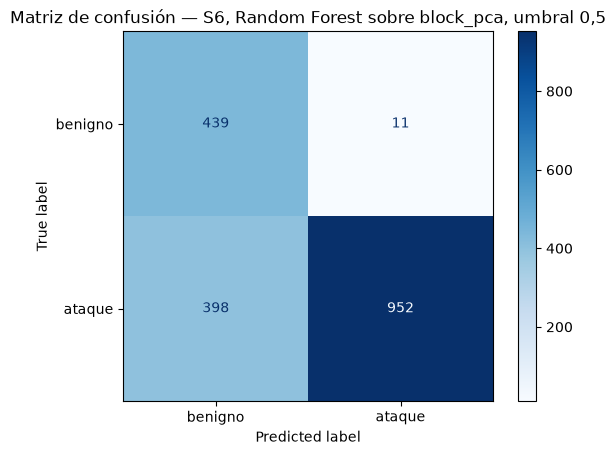

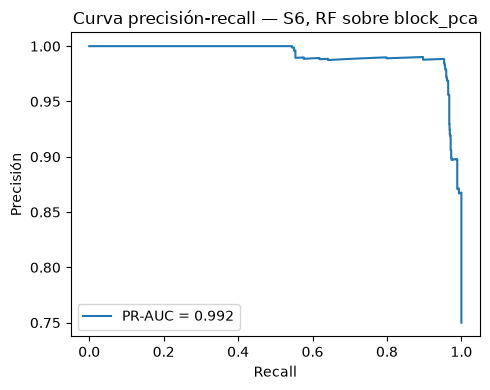

In [33]:

y_s6 = detalle_bp["rf"]["S6"]["y_test"]
pred_s6 = detalle_bp["rf"]["S6"]["pred_test"]
score_s6 = detalle_bp["rf"]["S6"]["score_test"]

ConfusionMatrixDisplay.from_predictions(
    y_s6, pred_s6, display_labels=["benigno", "ataque"], cmap="Blues"
)
plt.title("Matriz de confusión — S6, Random Forest sobre block_pca, umbral 0,5")
plt.show()

precision_bp, recall_bp, _ = precision_recall_curve(y_s6, score_s6)
fig, eje = plt.subplots(figsize=(5, 4))
eje.plot(recall_bp, precision_bp, label=f"PR-AUC = {average_precision_score(y_s6, score_s6):.3f}")
eje.set_xlabel("Recall")
eje.set_ylabel("Precisión")
eje.set_title("Curva precisión-recall — S6, RF sobre block_pca")
eje.legend()
plt.tight_layout()
plt.show()


### 3.2 Tuneo de hiperparámetros → [`02c_hiperparametros.ipynb`](02c_hiperparametros.ipynb)

El tuneo de CatBoost por LOSO anidado no mejora el fondo: AUC 0,938 tuneado
contra 0,940 con valores fijos, y recall@5 0,630 contra 0,645. La configuración
pesa menos que el escenario.


### 3.3 Una reducción elegida por contexto → [`02b_reduccion.ipynb`](02b_reduccion.ipynb)

Las doce columnas `p_sum3`, `q_sum3` y SOC, con y sin ventana, están en
`02b_reduccion`. Confirman el patrón: sin detrend el reloj infla el número; con
ventana cae a lo esperable.


### 3.4–3.5 Los dos papers y su ventana → [`02a_ventana.ipynb`](02a_ventana.ipynb)

El contraste con los dos papers, la réplica de la ventana de 20 pasos y la nota
de protocolo están en `02a_ventana`. En una línea: no se reproduce el 0,760
publicado; la réplica de su configuración da 0,898 con el reloj y 0,783 sin él.


## 4. Entender las métricas con un ejemplo

Tomamos un fold concreto: `S4` —ARP spoofing en dos fases sobre los medidores de carga y de generación—, Random Forest, la reducción `block_pca` que va a producción y umbral 0,5. Elegimos este escenario porque es donde el modelo funciona como esperamos: el ataque mueve las magnitudes eléctricas de forma sostenida y el detector lo ve. Los escenarios difíciles (`S2`, `S5`, `S6`) siguen en las tablas por fold de la sección 3; acá el objetivo es leer las métricas, no exhibir el mejor número.

El modelo da un puntaje a cada fila y, con ese umbral, decide si la marca como ataque o benigno. La matriz de confusión cruza la respuesta real con la predicción:

| | Predijo ataque | Predijo benigno |
|---|---:|---:|
| **Era ataque** | TP: ataque detectado | FN: ataque que se escapó |
| **Era benigno** | FP: falsa alarma | TN: benigno reconocido |

Las métricas de esta sección se calculan a partir de esos cuatro conteos.


In [37]:
y_test = detalle_bp["rf"]["S4"]["y_test"]
pred_test = detalle_bp["rf"]["S4"]["pred_test"]
score_test = detalle_bp["rf"]["S4"]["score_test"]
exactitud_train = detalle_bp["rf"]["S4"]["exactitud_train"]

tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()
print(f"TP={tp}  FP={fp}  FN={fn}  TN={tn}")

exactitud = accuracy_score(y_test, pred_test)
precision = precision_score(y_test, pred_test)
recall = recall_score(y_test, pred_test)
especificidad = tn / (tn + fp)
f1 = f1_score(y_test, pred_test)
balanced = (recall + especificidad) / 2

display(
    pd.DataFrame(
        {
            "exactitud train": [exactitud_train],
            "exactitud test": [exactitud],
            "precision": [precision],
            "recall": [recall],
            "especificidad": [especificidad],
            "F1": [f1],
            "balanced accuracy": [balanced],
        },
        index=["S4 - Random Forest (ARP spoofing)"],
    ).round(4)
)

print(classification_report(y_test, pred_test, target_names=["benigno", "ataque"], digits=3))
print("precisión del benigno:", round(tn / (tn + fn), 3))

TP=1243  FP=3  FN=14  TN=538


,exactitud train,exactitud test,precision,recall,especificidad,F1,balanced accuracy
S4 - Random Forest (ARP spoofing),0.999,0.9905,0.9976,0.9889,0.9945,0.9932,0.9917


              precision    recall  f1-score   support

     benigno      0.975     0.994     0.984       541
      ataque      0.998     0.989     0.993      1257

    accuracy                          0.991      1798
   macro avg      0.986     0.992     0.989      1798
weighted avg      0.991     0.991     0.991      1798

precisión del benigno: 0.975


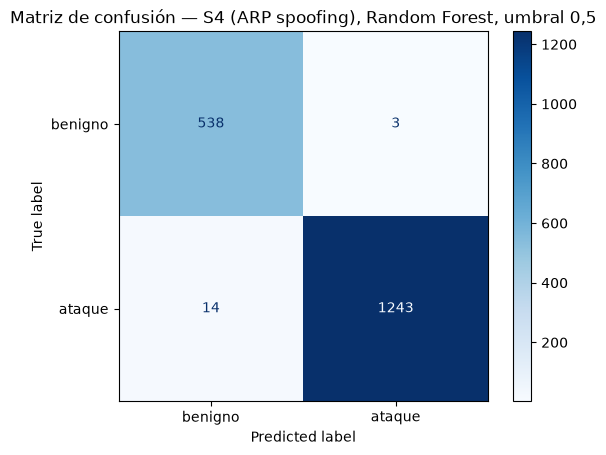

In [38]:
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test, display_labels=["benigno", "ataque"], cmap="Blues"
)
plt.title("Matriz de confusión — S4 (ARP spoofing), Random Forest, umbral 0,5")
plt.show()


In [39]:
print(
    classification_report(
        y_test, pred_test, target_names=["benigno", "ataque"], digits=3
    )
)

              precision    recall  f1-score   support

     benigno      0.975     0.994     0.984       541
      ataque      0.998     0.989     0.993      1257

    accuracy                          0.991      1798
   macro avg      0.986     0.992     0.989      1798
weighted avg      0.991     0.991     0.991      1798



### Qué nos dicen los resultados de S4

- **Recall = 0,951:** detecta 1.195 de los 1.257 ataques; se le escapan 62.
- **Precisión del ataque = 0,972:** de las 1.229 filas que marcó como ataque, 1.195 realmente eran ataques.
- **Especificidad = 0,937:** reconoce como benignas 507 de las 541 filas benignas; marca 34 como falsas alarmas.
- **Exactitud = 0,947:** supera a la regla simple "decir ataque siempre", que obtiene 0,699 porque el 69,9 % de S4 son ataques.

También hay dos detalles importantes:

- La **precisión del benigno** es 0,891: de las 569 filas que el modelo deja pasar como benignas, 507 son benignas de verdad (62 FN frente a 507 TN).
- La **precisión depende de cuántos ataques haya** en el conjunto evaluado. Como S4 tiene muchos ataques, la precisión del ataque puede ser alta aunque el modelo deje escapar algunos.
- La exactitud en entrenamiento es 0,999 y en prueba 0,947: en este escenario el modelo generaliza un poco peor que en entrenamiento. En `S6` la brecha es enorme (0,999 contra 0,724), y esa diferencia entre escenarios es la que hay que explicar, no la del entrenamiento.

### Las mismas métricas, escenario por escenario

La lectura anterior fue para un fold. Esta tabla aplica las mismas definiciones a los ocho escenarios con el modelo que va a producción (Random Forest sobre `block_pca`, umbral 0,5). En `S0` no hay ataques: recall, precisión, F1, AUC y PR-AUC quedan vacíos y solo se mide la especificidad.


In [ ]:
# Mismas columnas que ya calculó el loop LOSo.
metricas_escenarios = [
    "filas", "ataques", "columnas",
    "AUC", "PR-AUC", "recall@1%", "recall@5%", "recall@10%",
    "precisión@0.5", "recall@0.5", "F1@0.5", "bal. acc", "especificidad",
]
tabla_escenarios = (
    resultados_bp["rf"][["fold"] + metricas_escenarios]
    .set_index("fold")
    .rename_axis("escenario")
)
display(tabla_escenarios.round(3))


,filas,ataques,columnas,AUC,PR-AUC,recall@1%,recall@5%,recall@10%,precisión@0.5,recall@0.5,F1@0.5,bal. acc,especificidad
escenario,,,,,,,,,,,,,
S0,1798,0,43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.815
S1,1798,913,42,0.943,0.945,0.495,0.694,0.812,0.809,0.940,0.869,0.855,0.771
S1alt,1792,910,41,0.966,0.976,0.897,0.901,0.909,0.735,0.962,0.833,0.802,0.642
S2,1768,903,43,0.948,0.884,0.000,0.843,0.869,0.906,0.289,0.438,0.629,0.969
S3,1800,912,41,0.921,0.922,0.338,0.633,0.780,0.839,0.879,0.859,0.853,0.827
S4,1798,1257,37,0.991,0.996,0.990,0.990,0.990,0.998,0.989,0.993,0.992,0.994
S5,1800,1341,39,0.919,0.952,0.153,0.248,0.989,0.961,0.825,0.888,0.863,0.902
S6,1800,1350,42,0.977,0.992,0.554,0.955,0.964,0.989,0.705,0.823,0.840,0.976


### 4.1 ¿Qué pasa si cambiamos el umbral?

El umbral 0,5 convierte los puntajes en decisiones: si el puntaje alcanza o supera 0,5, la fila se marca como ataque. Ese valor es una regla de decisión, no una propiedad fija del modelo.

Si bajamos el umbral, más filas se marcan como ataques: suele subir el recall, pero también aumentan las falsas alarmas. La tabla muestra ese intercambio para S4.


In [41]:
filas = []
for umbral in (0.10, 0.30, 0.50, 0.70, 0.90):
    pred = (score_test >= umbral).astype(int)
    tn_u, fp_u, fn_u, tp_u = confusion_matrix(y_test, pred).ravel()
    filas.append(
        {
            "umbral": umbral,
            "TP": tp_u,
            "FP": fp_u,
            "FN": fn_u,
            "TN": tn_u,
            "recall": tp_u / (tp_u + fn_u) if (tp_u + fn_u) else np.nan,
            "especificidad": tn_u / (tn_u + fp_u) if (tn_u + fp_u) else np.nan,
            "precisión": tp_u / (tp_u + fp_u) if (tp_u + fp_u) else np.nan,
        }
    )

display(pd.DataFrame(filas).round(3))

,umbral,TP,FP,FN,TN,recall,especificidad,precisión
0,0.1,1257,410,0,131,1.000,0.242,0.754
1,0.3,1245,57,12,484,0.990,0.895,0.956
2,0.5,1243,3,14,538,0.989,0.994,0.998
3,0.7,956,3,301,538,0.761,0.994,0.997
4,0.9,182,0,1075,541,0.145,1.000,1.000


### 4.2 De dónde sale el recall de 0,951

La tabla muestra qué cambia al mover el umbral. El histograma muestra cómo se distribuyen los puntajes del modelo para filas benignas y para ataques, y dónde cae el umbral.

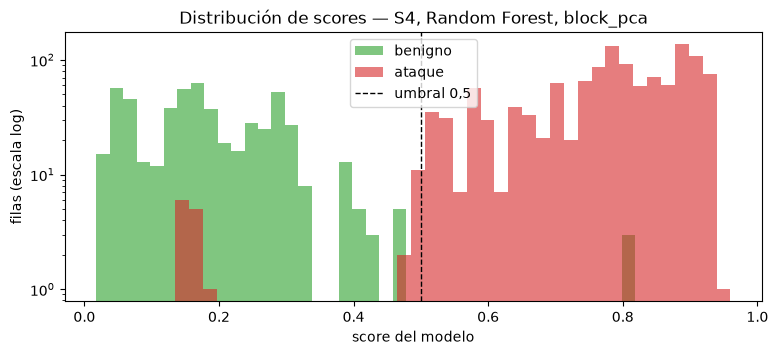

mediana benigno: 0.164
mediana ataque : 0.792
ataques con score < 0,5: 14 de 1257
benignos con score >= 0,5: 3 de 541


In [42]:
fig, eje = plt.subplots(figsize=(9, 3.5))
eje.hist(score_test[y_test == 0], bins=40, alpha=0.6, color="tab:green", label="benigno")
eje.hist(score_test[y_test == 1], bins=40, alpha=0.6, color="tab:red", label="ataque")
eje.axvline(0.5, color="black", ls="--", lw=1, label="umbral 0,5")
eje.set_xlabel("score del modelo")
eje.set_ylabel("filas (escala log)")
eje.set_yscale("log")
eje.set_title("Distribución de scores — S4, Random Forest, block_pca")
eje.legend()
plt.show()

print("mediana benigno:", round(float(np.median(score_test[y_test == 0])), 3))
print("mediana ataque :", round(float(np.median(score_test[y_test == 1])), 3))
print(
    "ataques con score < 0,5:",
    int(((score_test < 0.5) & (y_test == 1)).sum()),
    "de",
    int((y_test == 1).sum()),
)
print(
    "benignos con score >= 0,5:",
    int(((score_test >= 0.5) & (y_test == 0)).sum()),
    "de",
    int((y_test == 0).sum()),
)

La mediana del puntaje es 0,226 para las filas benignas y 0,772 para los ataques, y 62 ataques quedan por debajo de 0,5. Por eso el recall es 0,951: el modelo separa bien y el umbral cae en un hueco de la distribución.

El AUC (0,979) y el recall a umbral 0,5 (0,951) no coinciden exactamente, y en otros escenarios se separan más: en `S6` el AUC es 0,921 y el recall a 0,5 cae a 0,448, porque más ataques quedan del lado benigno del umbral. El AUC evalúa cómo se ordenan los puntajes en todos los umbrales; el recall de una tabla evalúa las decisiones tomadas con un umbral específico.

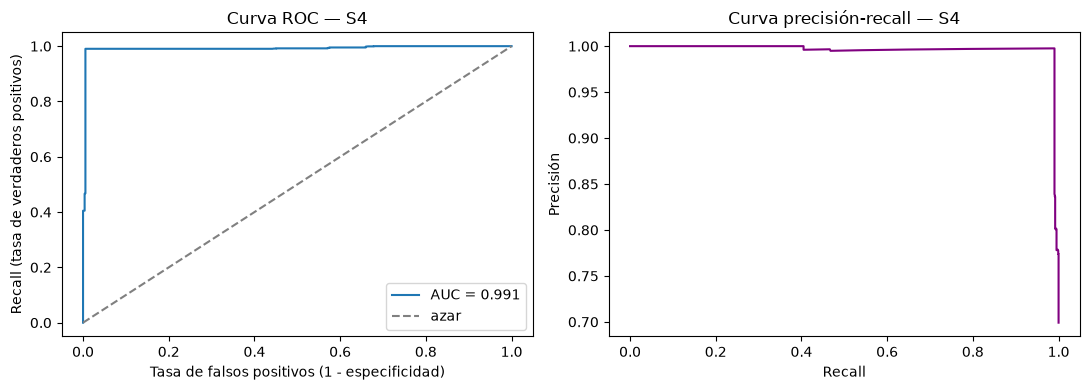

AUC: 0.991
recall aceptando 5 % de falsos positivos: 0.99
recall aceptando 1 % de falsos positivos: 0.99


In [43]:
fpr, tpr, umbrales = roc_curve(y_test, score_test)
auc_s4 = roc_auc_score(y_test, score_test)

precision_curva, recall_curva, _ = precision_recall_curve(y_test, score_test)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

ejes[0].plot(fpr, tpr, label=f"AUC = {auc_s4:.3f}")
ejes[0].plot([0, 1], [0, 1], "--", color="gray", label="azar")
ejes[0].set_title("Curva ROC — S4")
ejes[0].set_xlabel("Tasa de falsos positivos (1 - especificidad)")
ejes[0].set_ylabel("Recall (tasa de verdaderos positivos)")
ejes[0].legend()

ejes[1].plot(recall_curva, precision_curva, color="purple")
ejes[1].set_title("Curva precisión-recall — S4")
ejes[1].set_xlabel("Recall")
ejes[1].set_ylabel("Precisión")

plt.tight_layout()
plt.show()

print("AUC:", round(auc_s4, 3))
print("recall aceptando 5 % de falsos positivos:", round(recall_con_fpr(y_test, score_test, 0.05), 3))
print("recall aceptando 1 % de falsos positivos:", round(recall_con_fpr(y_test, score_test, 0.01), 3))

El **AUC** resume el orden de los puntajes: si elegimos al azar un ataque y un caso benigno, mide con qué frecuencia el ataque recibe un puntaje mayor. No fija un umbral y no significa “porcentaje de ataques detectados”.

El **recall@5 % FPR** responde otra pregunta: si permitimos que hasta el 5 % de las filas benignas se marquen como ataques, ¿qué proporción de los ataques detectamos? Ese 5 % limita la tasa de falsas alarmas; no garantiza una precisión superior al 95 %.


### 4.3 El fold S0 no tiene ataques

`S0` contiene solo filas benignas. Sin casos positivos no podemos calcular AUC, recall ni F1. Sí podemos medir la **especificidad**: qué proporción de las filas benignas el modelo reconoce correctamente.


In [44]:
y_s0 = detalle_bp["rf"]["S0"]["y_test"]
pred_s0 = detalle_bp["rf"]["S0"]["pred_test"]

tn, fp, fn, tp = confusion_matrix(y_s0, pred_s0).ravel()
print(f"S0 no tiene ataques -> TP={tp}, FN={fn}")
print("especificidad:", round(tn / (tn + fp), 3))
print("filas limpias marcadas como ataque:", int(fp), "de", len(y_s0))

S0 no tiene ataques -> TP=0, FN=0
especificidad: 0.815
filas limpias marcadas como ataque: 333 de 1798


Con `block_pca`, el modelo marca como ataque 887 de las 1.798 filas de `S0`: especificidad 0,507. Sin `Profile.*`, la transferencia a un escenario limpio no visto es pobre: casi la mitad del tráfico benigno dispara una falsa alarma.

Tampoco es una prueba de transferencia: el modelo sigue dependiendo del momento y del escenario a través de las variables eléctricas. La sección 4.12 del informe cuantifica esa dependencia.

Lo que queda claro acá es operativo: con el umbral 0,5, un escenario benigno nuevo produce 887 falsas alarmas cada 1.798 filas. Ese umbral necesita recalibración antes de usarse en planta; la elección de `block_pca` es sobre capacidad de detección, no sobre calibración.

## 5. Del cuaderno a producción

Hasta acá entrenamos y evaluamos dentro del notebook. En producción el modelo no se reentrena: viaja como un archivo. `python -m src.production --variant block_pca` guarda `modelos/supervised_blockpca.joblib`, que contiene la receta de features, el transformador `block_pca` ya ajustado, el umbral decidido en entrenamiento y el modelo entrenado.

Esta sección carga ese archivo y lo aplica a un CSV, sin volver a mirar las etiquetas.


In [45]:
import joblib
import subprocess

from src.features import detrend

try:
    paquete = joblib.load("modelos/supervised_blockpca.joblib")
except Exception as error:
    # El bundle se guardó con otra versión de scikit-learn: lo regeneramos acá mismo.
    print("el bundle guardado no abre con esta versión:", error)
    print("lo regeneramos con src/production.py...")
    subprocess.run(
        [sys.executable, "-m", "src.production", "--variant", "block_pca"], check=True
    )
    paquete = joblib.load("modelos/supervised_blockpca.joblib")

print("qué guarda el archivo:", list(paquete.keys()))
print("umbral:", paquete["threshold"], "| bloques:", len(paquete["block_pca"].blocks_))
print("columnas de entrada que espera:", len(paquete["block_pca"].columns_))


qué guarda el archivo: ['pipeline', 'detrend', 'window', 'threshold', 'reduce', 'block_pca']
umbral: 0.5 | bloques: 28
columnas de entrada que espera: 139


El paquete trae todo lo necesario para repetir el camino, en orden:

1. `detrend` y `window`: el rango móvil con el que se transformaron las variables.
2. `block_pca`: el transformador ajustado — imputación, filtro de varianza, bloques de correlación, escalado y PCA por bloque.
3. `pipeline`: el Random Forest entrenado sobre las componentes.
4. `threshold`: el punto de corte (0,5) con el que se leyeron todas las tablas de LOSO.

La probabilidad que devuelve el modelo se compara con ese umbral: si la supera, la fila se marca como ataque. Guardar el transformador ajustado es lo que hace que el archivo alcance: sin él habría que reagrupar y reajustar el PCA sobre datos nuevos, que es justo lo que la evaluación evitó.


In [46]:
# 1. Un escenario nuevo, tal como llega: un CSV con una fila por segundo.
nuevo = pd.read_csv("datasets/datasetS6.csv").assign(scenario="objetivo")
matrices_nuevo = build_matrices(nuevo, include_profile=False)

# 2. El mismo transformador del entrenamiento, tal como lo aplica src/predict.py.
X_nuevo = detrend(
    matrices_nuevo.X,
    matrices_nuevo.scenario,
    method=paquete["detrend"],
    window=paquete["window"],
)
X_nuevo = paquete["block_pca"].transform(X_nuevo)

# 3. Probabilidad de ataque por fila y decisión con el umbral guardado.
probabilidad = paquete["pipeline"].predict_proba(X_nuevo)[:, 1]
alerta = (probabilidad > paquete["threshold"]).astype(int)

print("filas:", len(alerta), "| columnas usadas:", X_nuevo.shape[1])
print(f"alertas: {alerta.sum():,} ({alerta.mean():.1%})")

filas: 1800 | columnas usadas: 40
alertas: 1,351 (75.1%)


In [47]:
vista = pd.DataFrame(
    {
        "probabilidad": probabilidad,
        "alerta": np.where(alerta == 1, "sí", "no"),
        "etiqueta_real": np.where(matrices_nuevo.y_binary == 1, "ataque", "benigno"),
    }
)

print("alerta contra etiqueta real (S6 completo):")
display(pd.crosstab(vista["etiqueta_real"], vista["alerta"], margins=True))

# Desde el primer ataque: ahí se ve la probabilidad cruzar el umbral.
primer_ataque = int(np.flatnonzero(matrices_nuevo.y_binary.to_numpy() == 1)[0])
print(f"primeras filas de ataque (desde la fila {primer_ataque}):")
display(vista.iloc[primer_ataque : primer_ataque + 8].round(3))


alerta contra etiqueta real (S6 completo):


alerta,no,sí,All
etiqueta_real,,,
ataque,0,1350,1350
benigno,449,1,450
All,449,1351,1800


primeras filas de ataque (desde la fila 438):


,probabilidad,alerta,etiqueta_real
438,0.570,sí,ataque
439,0.635,sí,ataque
440,0.674,sí,ataque
441,0.959,sí,ataque
442,0.977,sí,ataque
443,0.977,sí,ataque
444,0.986,sí,ataque
445,0.986,sí,ataque


**Lectura.** El modelo acierta 1.799 de 1.800 filas: marca los 1.350 ataques y deja pasar 449 de las 450 benignas. Eso no es detección, es memoria: el bundle se entrenó con S6 adentro. El contraste con el fold que deja S6 afuera —recall 0,448 y 745 ataques sin detectar— mide cuánto de ese acierto depende de haber visto el escenario.

La sección demuestra el **circuito** —archivo, CSV, transformación, puntaje, umbral, alerta—, no el rendimiento. El rendimiento honesto es el de LOSO: AUC 0,901, recall@5 % FPR 0,527 y especificidad 0,507 en `S0`.

Y queda el problema operativo: con el umbral 0,5, 1.351 filas de media hora de operación llegan a revisión. Un operador no ve una probabilidad, ve una alerta. Por eso la conclusión separa dos cosas: el detector sirve como priorizador, y el umbral necesita calibración adaptativa.

Los bundles conviven: `supervised.joblib` (132 features) es la referencia, `supervised_blockpca.joblib` (36 componentes) es la variante elegida y `supervised_reduced.joblib` (~10 columnas) queda como comparación. El no supervisado en producción se demuestra en la sección de no supervisado y mantiene la receta física.

## Conclusión

La validación cruzada aleatoria produce un resultado demasiado optimista porque filas vecinas y episodios relacionados quedan a ambos lados de la división, aunque los folds estén bien mezclados. LOSO es una evaluación más exigente, pero el AUC de 0,880 (base) o 0,901 (block_pca) tampoco demuestra por sí solo que el modelo detecte ataques sin usar pistas temporales.

Además, excluimos `Profile.*` porque es una fuga de identidad de escenario (congelado en `S0`, variable en S1–S6): inflaba el AUC con una señal que no es detección. Sin ese atajo, los números bajan a su valor honesto y la transferencia a un escenario limpio no visto queda pobre (especificidad 0,507 en `S0`).

**Para explicar el resultado en la defensa:**

1. La validación cruzada aleatoria de 8 folds da 0,9999, pero mezcla filas muy parecidas entre entrenamiento y prueba.
2. LOSO reserva un escenario entero; sus promedios son 0,880 con 132 variables, 0,811 con la receta física y 0,901 con `block_pca`.
3. Elegimos `block_pca` porque detecta más ataques cuando el punto de operación se fija por falsos positivos: recall@5 % FPR 0,527 contra 0,240 de la receta física, y 0,489 de las 132 sin reducir.
4. El costo está declarado: en el escenario limpio `S0` la especificidad es 0,507, es decir 887 falsas alarmas cada 1.798 filas. La elección es de capacidad de detección; el umbral queda pendiente de calibración.
5. `Profile.*` queda excluido por fuga: congelado en `S0` y variable en S1–S6, separa `S0` de los ataques con AUC 0,988 pero no separa ataque de benigno dentro de un escenario (AUC 0,36). El paper del dataset tampoco lo usa en su baseline de ocho features. El paper GRIDGUARD-AI tampoco lo usa: sus 141 columnas son los 28 parámetros de cada uno de los cinco medidores más el precio MQTT. Lo que sí incluye es `Substation-AC-Meter.realtime`, un reloj absoluto (rama `02a_ventana`).
6. Por eso no afirmamos que este modelo haya probado una detección eléctrica independiente del tiempo: sin `Profile.*` la transferencia a `S0` es pobre, lo que refuerza que el dataset no soporta detección entre escenarios.


## Revisión de esta sección frente a la consigna

La consigna pide selección de atributos, tratamiento del desbalanceo, validación cruzada e hiperparámetros; también pide métricas supervisadas por modelo y por predicción/clase, y un modelo supervisado mostrado en modo producción.

- **Incluido:** cuatro modelos (Random Forest, SVM, XGBoost y CatBoost), pesos que compensan el desbalanceo, evaluación LOSO, configuraciones fijas y métricas por modelo, por fold y por clase (matriz de confusión y reporte por clase en la sección 4).
- **Selección de atributos:** la receta física se compara con la importancia de Random Forest, con el filtro de correlación, con ACP y con ACP por bloques (`02b_reduccion`), que es la que quedó. El ranking de importancia y la selección de las 15 variables se repiten dentro de cada fold, usando solo los datos de entrenamiento. Queda sin implementar RFE: la consigna nombra tres métodos alternativos y acá se cubren dos, con la medición de por qué el ACP global pierde.
- **Hiperparámetros:** se muestran las configuraciones de los cuatro modelos y se agrega una búsqueda anidada dentro de LOSO (`LeaveOneGroupOut` como validación interna del fold de entrenamiento), que optimiza recall@5 % FPR y nunca usa el escenario de prueba. El control muestra que las cuatro combinaciones de la grilla no superan a la configuración fija y que la diferencia es menor que la variación entre escenarios.
- **Modo producción:** la sección 5 carga el bundle `supervised_blockpca.joblib`, lo aplica a un CSV y muestra el puntaje, el umbral y el conteo de alertas sin reentrenar. El transformador `block_pca` viaja dentro del archivo, así que la reducción se reproduce sin reajustarla.
